# Churn Prediction 

*A bank has certain number of customers, and based on the inputs (or, behaviours) we have to predict whether a customer can churned in upcoming time or not!*

*If the model predicts the Great Possibility of Churn, then from the business point of view we can adopt preventions methods!*

In [61]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [ ]:

# import relevenat libraries for the project!

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns



### 1. Read the Data!

In [62]:
# read the data!
df = pd.read_csv("Churn_Modelling.csv")

In [63]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [7]:
df.shape

(10000, 14)

### 2. Data Cleaning!

In [8]:
df.dtypes

RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [9]:
df.isna().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [10]:
for col in df.columns:
    print(col)
    print(df[col].dtype)
    print(df[col].nunique())
    print(df[col].unique())
    print()
    print("*"*80)
    print()

RowNumber
int64
10000
[    1     2     3 ...  9998  9999 10000]

********************************************************************************

CustomerId
int64
10000
[15634602 15647311 15619304 ... 15584532 15682355 15628319]

********************************************************************************

Surname
object
2932
['Hargrave' 'Hill' 'Onio' ... 'Kashiwagi' 'Aldridge' 'Burbidge']

********************************************************************************

CreditScore
int64
460
[619 608 502 699 850 645 822 376 501 684 528 497 476 549 635 616 653 587
 726 732 636 510 669 846 577 756 571 574 411 591 533 553 520 722 475 490
 804 582 472 465 556 834 660 776 829 637 550 698 585 788 655 601 656 725
 511 614 742 687 555 603 751 581 735 661 675 738 813 657 604 519 664 678
 757 416 665 777 543 506 493 652 750 729 646 647 808 524 769 730 515 773
 814 710 413 623 670 622 785 605 479 685 538 562 721 628 668 828 674 625
 432 770 758 795 686 789 589 461 584 579 663 682 793 691 48

In [11]:
# df.drop( columns = ['RowNumber'], inplace=True)

In [12]:
# flow of our aapproach!

# 11 useful predictive features
#         ↓
# EDA
#         ↓
# Feature engineering
#         ↓
# Train/test split
#         ↓
# Preprocessing
#         ↓
# Classification model
#         ↓
# Churn prediction


# ****************************************************************************************************


# Some Research on Data!

# Yes — CustomerId can help in Feature Engineering, but not as a raw feature.

# Use it temporarily to create historical/customer-level features, such as:

# previous_transactions
# customer_avg_balance
# customer_avg_products
# customer_tenure_history

# Then drop CustomerId before modeling.

# So:

# CustomerId → FE → useful aggregate features → drop CustomerId → ML ✅


# If your new FE columns have nulls, handle them in the preprocessing pipeline, not manually.

# Typical approach:

# Numeric FE → median imputation
# Categorical FE → most-frequent / "Unknown"
# If null has business meaning → create a missing indicator or map appropriately.

# So:

# Feature Engineering → possible NaNs → Train/Test Split → Pipeline Imputation → Model

# For this project: drop Surname and use legitimate business features like age, geography, tenure,
# products, balance, activity, etc.

In [13]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [14]:
# cleaning func!
def clean_data(df):
    df.drop(columns=['RowNumber', 'Surname', 'CustomerId'], inplace=True )

    # return df



In [15]:
clean_data(df)


### 3. Feature Engineering!

In [16]:

# 1. Whether customer has zero account balance
df['zero_balance'] = (df['Balance'] == 0).astype(int)

# 2. Average balance per product held
df['balance_per_product'] = (
    df['Balance'] / df['NumOfProducts'].replace(0, np.nan)
)


In [17]:
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited', 'zero_balance', 'balance_per_product'],
      dtype='object')

### 4. EDA! (to know data patterns and the column importances!)

In [18]:
# Target is -> "Exited"

# so, make sure to hold our thinking approach around this target only!



In [19]:
# df

In [20]:
# extracting the num and cat cols from the data for the analysis part! (not for ML)

num_cols = df.select_dtypes(include="number").columns.to_list()
# remove target from the result!
num_cols.remove("Exited")
print("num_cols : ", num_cols)

print()

cat_cols = df.select_dtypes(include="object").columns.to_list()
print("cat_cols : ", cat_cols)

num_cols :  ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'zero_balance', 'balance_per_product']

cat_cols :  ['Geography', 'Gender']


CreditScore skewness is: -0.07160660820092675


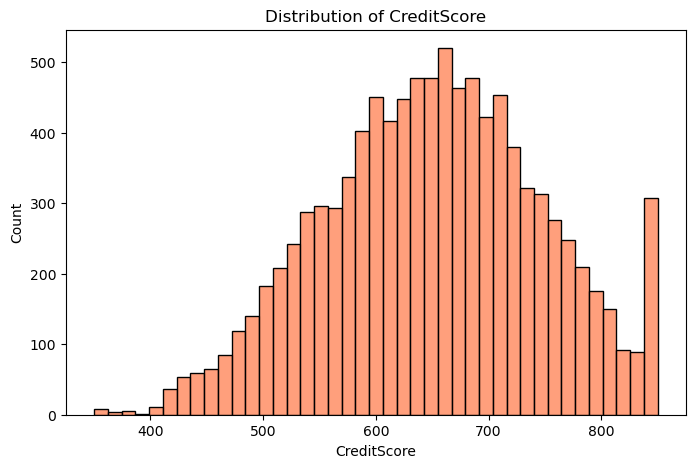


********************************************************************************

Age skewness is: 1.0113202630234552


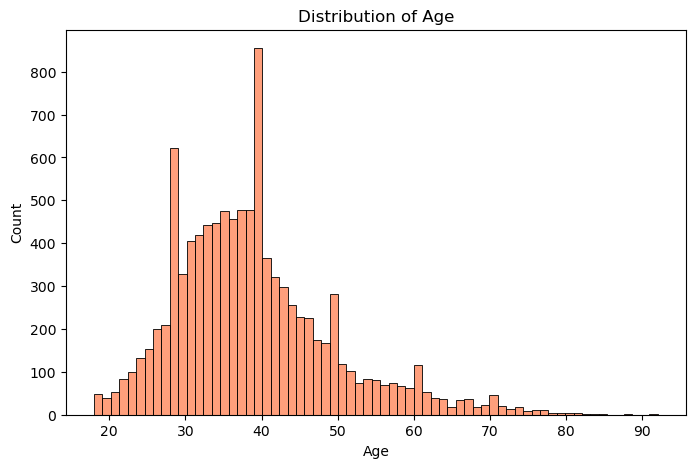


********************************************************************************

Tenure skewness is: 0.010991457977179039


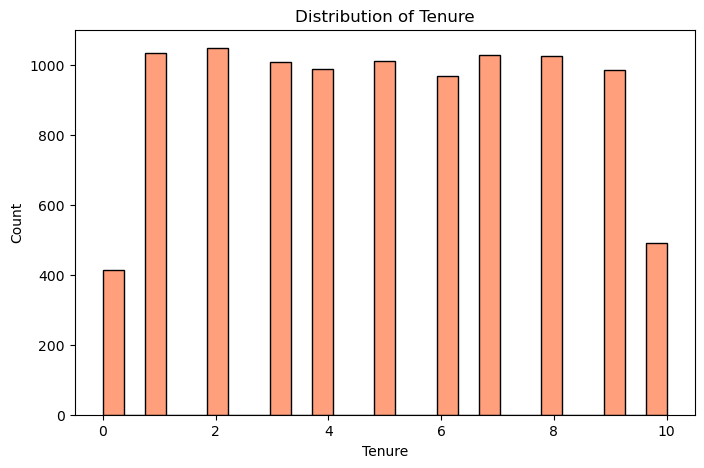


********************************************************************************

Balance skewness is: -0.14110871094154379


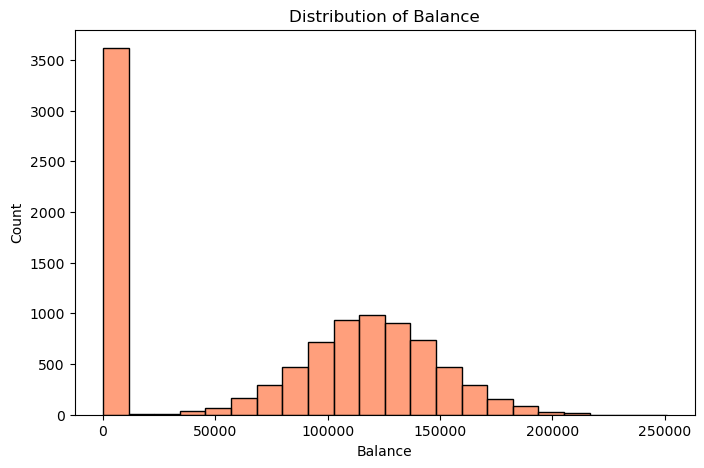


********************************************************************************

NumOfProducts skewness is: 0.7455678882823168


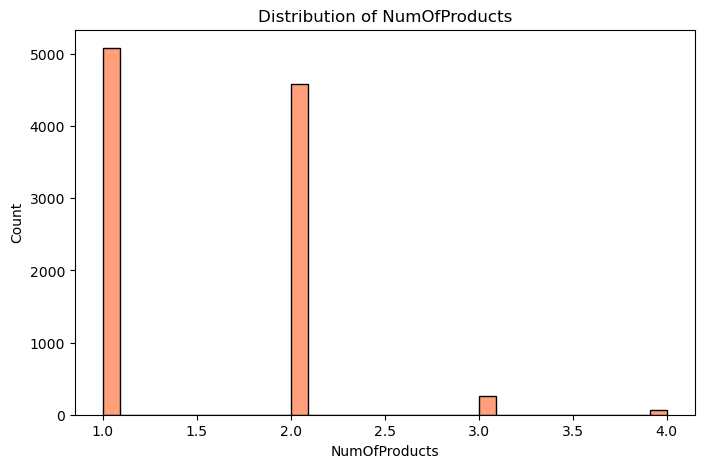


********************************************************************************

HasCrCard skewness is: -0.9018115952400573


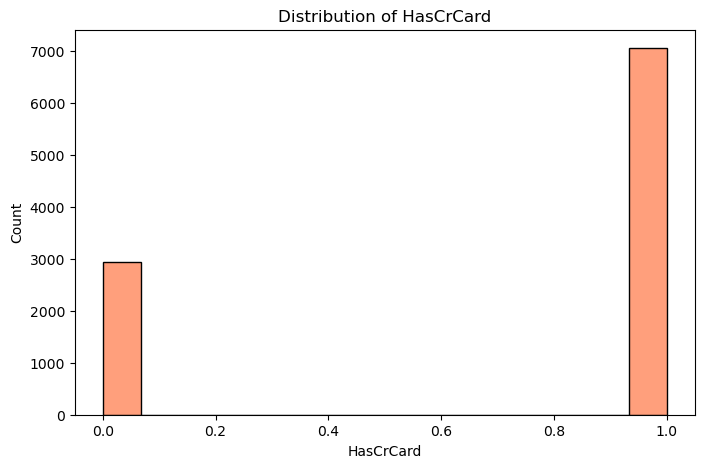


********************************************************************************

IsActiveMember skewness is: -0.06043662833499078


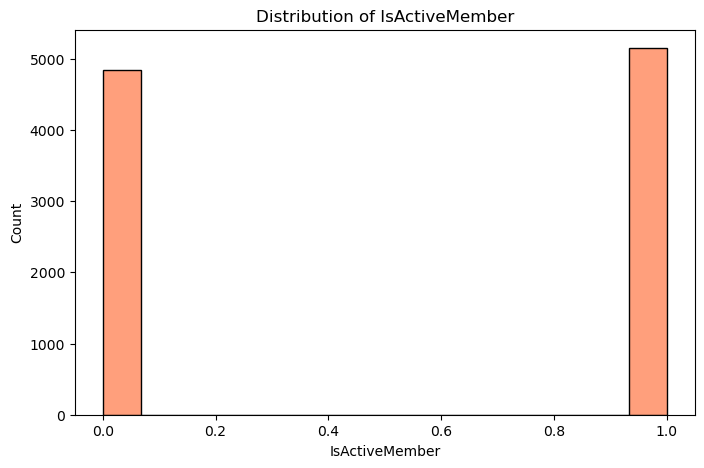


********************************************************************************

EstimatedSalary skewness is: 0.002085357661558513


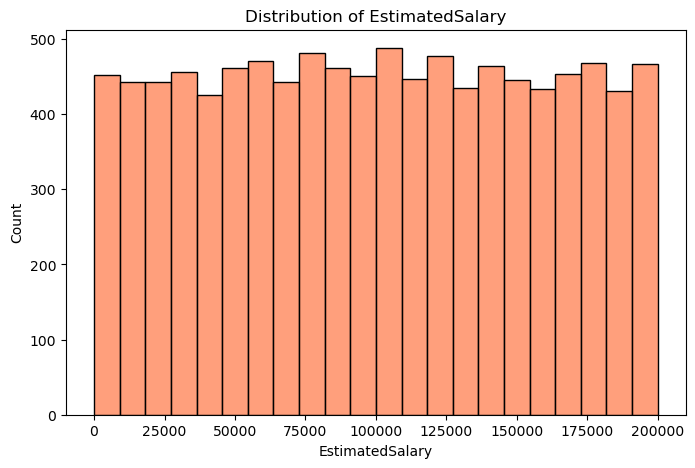


********************************************************************************

zero_balance skewness is: 0.5757456308827007


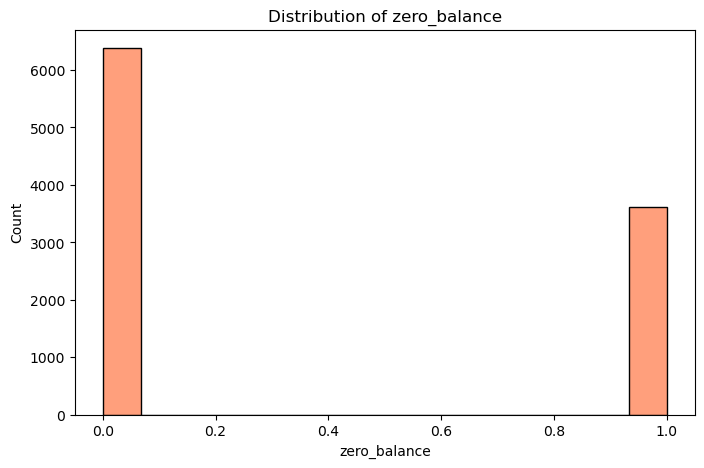


********************************************************************************

balance_per_product skewness is: 0.27767522164555203


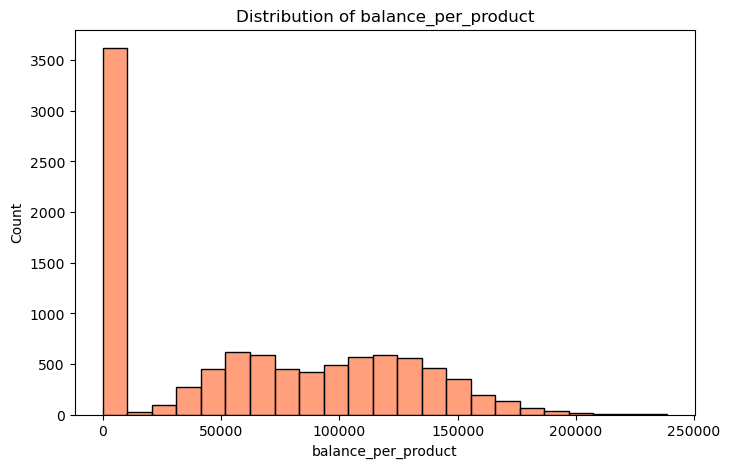


********************************************************************************



In [21]:
# analysis for numerical columns!:

for col in num_cols:
    
    sk = df[col].skew()
    print(f"{col} skewness is: {sk}")
    
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], color="coral")
    plt.title(f"Distribution of {col}")
    plt.show()
    
    print()
    print("*" * 80)
    print()
    

In [22]:
# data is slightly tilted either left or right side, no not need much col trasformations!


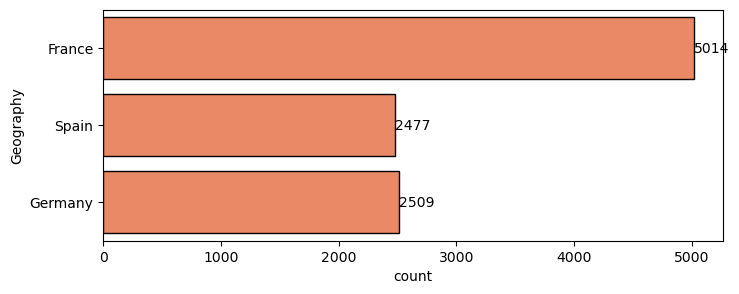


********************************************************************************



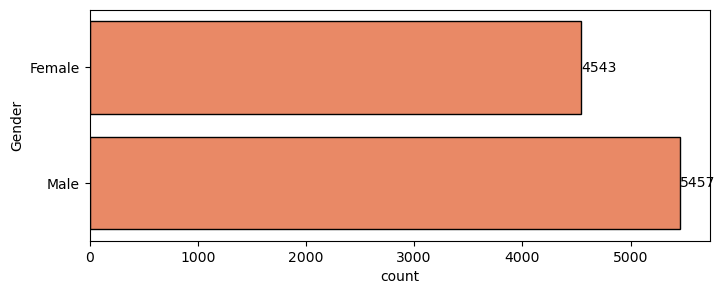


********************************************************************************



In [23]:
# analysis for categorical cols!

for col in cat_cols:

    plt.figure(figsize=(8, 3))
    bars = sns.countplot(df[col], color="coral", edgecolor="black")
    plt.bar_label(bars.containers[0])
    plt.show()
    print()
    print("*"*80)
    print()
    

<Axes: xlabel='count', ylabel='Gender'>

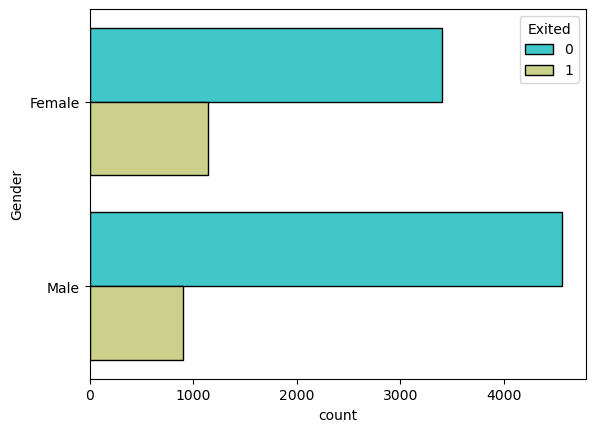

In [24]:
# to check default cases gender wise!

sns.countplot(y=df['Gender'], hue=df['Exited'], palette="rainbow", edgecolor="black")

In [25]:
# we can see that deafult cases is not affected by the gender types!


In [26]:
df.corr(numeric_only=True)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,zero_balance,balance_per_product
CreditScore,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.005458,0.025651,-0.001384,-0.027094,-0.008380,0.002054
Age,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.011721,0.085472,-0.007201,0.285323,-0.034950,0.032565
Tenure,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.022583,-0.028362,0.007784,-0.014001,0.015235,-0.012042
Balance,0.006268,0.028308,-0.012254,1.000000,-0.304180,-0.014858,-0.010084,0.012797,0.118533,-0.922780,0.901862
NumOfProducts,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.003183,0.009612,0.014204,-0.047820,0.329294,-0.594726
HasCrCard,-0.005458,-0.011721,0.022583,-0.014858,0.003183,1.000000,-0.011866,-0.009933,-0.007138,0.018358,-0.015970
IsActiveMember,0.025651,0.085472,-0.028362,-0.010084,0.009612,-0.011866,1.000000,-0.011421,-0.156128,0.004116,-0.011983
EstimatedSalary,-0.001384,-0.007201,0.007784,0.012797,0.014204,-0.009933,-0.011421,1.000000,0.012097,-0.014486,0.002229
Exited,-0.027094,0.285323,-0.014001,0.118533,-0.047820,-0.007138,-0.156128,0.012097,1.000000,-0.122357,0.109806
zero_balance,-0.008380,-0.034950,0.015235,-0.922780,0.329294,0.018358,0.004116,-0.014486,-0.122357,1.000000,-0.832834


<Axes: >

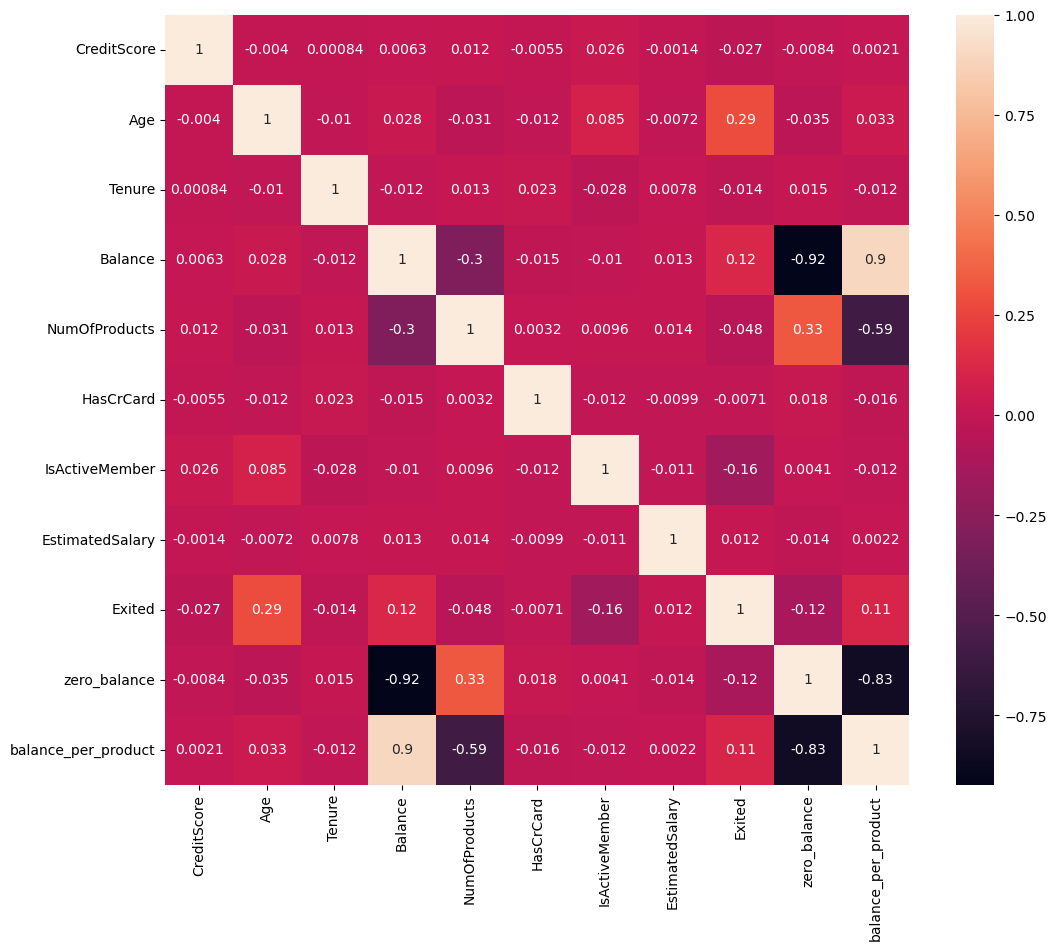

In [27]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [28]:
# with respect, to target, we can see that their a non-linear complex type of relationship!

# so, their is a possibilty that linear model (log reg.) would not perform well!

In [29]:
# df.isna().sum()

### 5. Split the data into X, and y

In [30]:

X = df.drop(columns=['Exited'])
y = df[['Exited']]

print("X: ", X.shape)
print("y: ", y.shape)


X:  (10000, 12)
y:  (10000, 1)


In [31]:
# X.isna().sum()

### 6. Split data into training  and testing parts!

In [32]:


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.20)

print(X_train.shape)
print(y_train.shape)
print()
print(X_test.shape)
print(y_test.shape)

(8000, 12)
(8000, 1)

(2000, 12)
(2000, 1)


In [33]:
# again seperating num and cat cols for pipelines!
num_cols = X.select_dtypes(include="number").columns.to_list()
cat_cols = X.select_dtypes(include="object").columns.to_list()

### 7. Data Preprocessing!

In [34]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline 
from sklearn.compose import ColumnTransformer

ohe = OneHotEncoder()

sc = StandardScaler()

preprocessor = ColumnTransformer([
    ('num', ohe, cat_cols),
    ('cat', sc, num_cols)
])

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,categories,'auto'
,drop,None
,sparse_output,True


In [35]:
# checking the preprocessor working!
X_train_transform = preprocessor.fit_transform(X_train)

X_train_transform

array([[ 1.        ,  0.        ,  0.        , ...,  1.36766974,
         1.31969839, -1.10025712],
       [ 0.        ,  1.        ,  0.        , ...,  1.6612541 ,
        -0.7577489 , -0.04507796],
       [ 0.        ,  0.        ,  1.        , ..., -0.25280688,
        -0.7577489 ,  0.92392807],
       ...,
       [ 1.        ,  0.        ,  0.        , ..., -0.1427649 ,
         1.31969839, -1.10025712],
       [ 1.        ,  0.        ,  0.        , ..., -0.05082558,
        -0.7577489 ,  2.25564209],
       [ 0.        ,  1.        ,  0.        , ..., -0.81456811,
        -0.7577489 ,  1.50910359]], shape=(8000, 15))

In [36]:
# pd.DataFrame
features = preprocessor.get_feature_names_out()
# features

pd.DataFrame(X_train_transform, columns=features)

,num__Geography_France,num__Geography_Germany,num__Geography_Spain,num__Gender_Female,num__Gender_Male,cat__CreditScore,cat__Age,cat__Tenure,cat__Balance,cat__NumOfProducts,cat__HasCrCard,cat__IsActiveMember,cat__EstimatedSalary,cat__zero_balance,cat__balance_per_product
0,1.0,0.0,0.0,0.0,1.0,0.356500,-0.655786,0.345680,-1.218471,0.808436,0.649203,0.974817,1.367670,1.319698,-1.100257
1,0.0,1.0,0.0,0.0,1.0,-0.203898,0.294938,-0.348369,0.696838,0.808436,0.649203,0.974817,1.661254,-0.757749,-0.045078
2,0.0,0.0,1.0,0.0,1.0,-0.961472,-1.416365,-0.695393,0.618629,-0.916688,0.649203,-1.025834,-0.252807,-0.757749,0.923928
3,1.0,0.0,0.0,1.0,0.0,-0.940717,-1.131148,1.386753,0.953212,-0.916688,0.649203,-1.025834,0.915393,-0.757749,1.292584
4,1.0,0.0,0.0,0.0,1.0,-1.397337,1.625953,1.386753,1.057449,-0.916688,-1.540351,-1.025834,-1.059600,-0.757749,1.407436
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,1.0,0.0,0.0,0.0,1.0,1.207474,1.435808,1.039728,-0.102301,-0.916688,0.649203,0.974817,-0.539860,-0.757749,0.129581
7996,1.0,0.0,0.0,1.0,0.0,0.314989,1.816097,-1.389442,-1.218471,-0.916688,0.649203,0.974817,-1.733882,1.319698,-1.100257
7997,1.0,0.0,0.0,1.0,0.0,0.865009,-0.085351,-1.389442,-1.218471,2.533560,-1.540351,-1.025834,-0.142765,1.319698,-1.100257
7998,1.0,0.0,0.0,0.0,1.0,0.159323,0.390011,1.039728,1.827259,-0.916688,0.649203,-1.025834,-0.050826,-0.757749,2.255642


### 8. Model Building!

as this is the classification problem, as we would prefere the algorithm like Log Regr, Decision Tree, etc.

#### 1. Logistic Regression!

In [37]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()

log_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', log_reg)
])
log_pipeline

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
log_pipeline.fit(X_train, y_train)

c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [39]:
y_pred = log_pipeline.predict(X_test)

In [40]:
# model evaluations!

from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, y_pred)
acc



0.8135

In [41]:
# 81% accuarcy from Logistic Regression Model!

# model is able to correctly classifyc about 81% of data points!

In [42]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [43]:
# we can clearly see, that the classes are Imbalanced, so we cannot rely on Accuracy Only!

# so, using more metrics for eval!

In [44]:
from sklearn.metrics import classification_report

class_repo = classification_report(y_test, y_pred)

print(class_repo)

              precision    recall  f1-score   support

           0       0.83      0.96      0.89      1607
           1       0.57      0.20      0.30       393

    accuracy                           0.81      2000
   macro avg       0.70      0.58      0.60      2000
weighted avg       0.78      0.81      0.78      2000



In [45]:
# Ques: do we want to capture max. defaulter?  

# Ques: do we want to reduce the false capturing as defaulters!

# Recall is the best, that we can rely as per the goal of 1st ques!


In [46]:
# Recall -> 0.20 for 1 class (Deafulters/churn) -> so, we need to improve this!

#### 2. Decission Tree!

In [71]:
# model building !
from sklearn.tree import DecisionTreeClassifier

# model pipeline!
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('dt_model', DecisionTreeClassifier()  )
])

dt_pipeline

,steps,"[('preprocessor', ...), ('dt_model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [72]:
# model training!
dt_pipeline.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('dt_model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [49]:
# model predictions!
y_pred = dt_pipeline.predict(X_test)


In [50]:
# model evaluations!
class_repo = classification_report(y_test, y_pred)

print(class_repo)


              precision    recall  f1-score   support

           0       0.88      0.85      0.87      1607
           1       0.46      0.51      0.48       393

    accuracy                           0.79      2000
   macro avg       0.67      0.68      0.67      2000
weighted avg       0.79      0.79      0.79      2000



In [51]:
# this shows the drastic improvements n capturing the default cases, as compared to Logistic Rgeression mOdle!

# this is able to capture, about 50% of default cases!

In [52]:
DecisionTreeClassifier()

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [73]:
X_train.shape

(8000, 12)

#### 3. Random Forest Algorithm

In [53]:
# model training!
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier()

# model pipeline!
rfc_pipeline = Pipeline([
    ('preprocessor', preprocessor ),
    ('rfc_model', rfc)
])

rfc_pipeline

,steps,"[('preprocessor', ...), ('rfc_model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [54]:
# model training!
rfc_pipeline.fit(X_train, y_train)

c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,steps,"[('preprocessor', ...), ('rfc_model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [55]:
# model predictions!
y_pred = rfc_pipeline.predict(X_test)


In [56]:
# model evaluations!
class_repo = classification_report(y_test, y_pred)

print(class_repo)


              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.76      0.48      0.58       393

    accuracy                           0.87      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.87      0.85      2000



In [57]:
# rfc imprpvements ! = random forest with some better hyper parameters!

from sklearn.metrics import precision_score, recall_score, roc_auc_score, f1_score, confusion_matrix
# Model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Full pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', rf_model)
])

# Train
rf_pipeline.fit(X_train, y_train)

# Predictions
y_pred = rf_pipeline.predict(X_test)
y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Accuracy : 0.8665
Precision: 0.7916666666666666
Recall   : 0.4351145038167939
F1 Score : 0.5615763546798029
ROC-AUC  : 0.8724552728124886

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1607
           1       0.79      0.44      0.56       393

    accuracy                           0.87      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.86      0.87      0.85      2000


Confusion Matrix:
[[1562   45]
 [ 222  171]]


In [58]:
# GridSearchCV

#### 4. Gradient Boosting Algorithm!

In [59]:
from sklearn.ensemble import GradientBoostingClassifier

# Model
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Full pipeline
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', gb_model)
])

# Train
gb_pipeline.fit(X_train, y_train)

# Predictions
y_pred = gb_pipeline.predict(X_test)
y_prob = gb_pipeline.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Accuracy : 0.8675
Precision: 0.7580645161290323
Recall   : 0.47837150127226463
F1 Score : 0.5865834633385335
ROC-AUC  : 0.8733791886957664

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.76      0.48      0.59       393

    accuracy                           0.87      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.87      0.86      2000


Confusion Matrix:
[[1547   60]
 [ 205  188]]


#### Hyperparameter Tuning & Cross-Validation!

In [60]:
from sklearn.model_selection import GridSearchCV

# Model
dt = DecisionTreeClassifier(random_state=42)

# Hyperparameter grid
param_grid = {
    'dt_model__max_depth': [3, 5, 7, 10, None],
    'dt_model__min_samples_split': [2, 5, 10],
    'dt_model__min_samples_leaf': [1, 2, 5],
    'dt_model__criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# Best results
print("Best Parameters:", grid_search.best_params_)
print("Best CV Recall:", grid_search.best_score_)

# Best model
best_dt_model = grid_search.best_estimator_

# Test predictions
y_pred = best_dt_model.predict(X_test)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best Parameters: {'dt_model__criterion': 'entropy', 'dt_model__max_depth': None, 'dt_model__min_samples_leaf': 5, 'dt_model__min_samples_split': 10}
Best CV Recall: 0.5133534732003855


In [67]:
dt_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=None,
    min_samples_leaf=5,
    min_samples_split=10
)
dt



,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [76]:

dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('dt_model', dt_model)
])

# Train the model
dt_pipeline.fit(X_train, y_train)

# Predictions
# y_pred = dt_pipeline.predict(X_test)

,steps,"[('preprocessor', ...), ('dt_model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [78]:
import joblib

joblib.dump(dt_pipeline, "dt_model_pipeline.pkl")
print("Done!")

Done!


### 9. Conclusion!

so, we came to the conclusion that the Decision Tree best Recall is 51%, and with best parameters as :

{'dt_model__criterion': 'entropy', 'dt_model__max_depth': None, 'dt_model__min_samples_leaf': 1, 'dt_model__min_samples_split': 2}
